# Week 3: Supervised Models (KNN, Decision Tree, Logistic Regression)
**Name:** Numan Ali  |  **Dataset:** Heathcare_dataset

**Goal:** train three classifiers on my own dataset, judge them with accuracy, confusion matrix and F1-score, and decide which model is best for my problem.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

# ====== CHANGE THIS ======
TARGET = "status"
DROP_COLS = ["patient_id", "first_name", "last_name", "phone", "email",
             "admission_date", "discharge_date"]
DATA_PATH = "healthcare_data.csv"
# =========================

try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    pass

df = pd.read_csv(DATA_PATH)
print("Original shape (rows, columns):", df.shape)
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
print("Shape after dropping ID/contact/date columns:", df.shape)
df.head()

Saving healthcare_data.csv to healthcare_data.csv
Original shape (rows, columns): (17498, 14)
Shape after dropping ID/contact/date columns: (17498, 7)


,age,gender,department,diagnosis,treatment,status,bill_amount
0,60,Male,Pediatrics,Migraine,Medication,Admitted,100900.97
1,11,Other,Dermatology,Diabetes,Medication,Discharged,120905.91
2,2,Female,Neurology,Asthma,Medication,Under Treatment,170672.18
3,22,Other,Cardiology,Cancer,Observation,Discharged,149977.74
4,8,Female,Neurology,Cancer,Observation,Under Treatment,160039.43


In [2]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else "None")
print("\nDuplicate rows:", df.duplicated().sum())
print("\nColumn types:")
print(df.dtypes)

Missing values per column:
None

Duplicate rows: 0

Column types:
age              int64
gender          object
department      object
diagnosis       object
treatment       object
status          object
bill_amount    float64
dtype: object


In [3]:
# --- Fix duplicates and missing values ---
if TARGET not in df.columns:
    raise KeyError(f"TARGET '{TARGET}' not found. Columns are: {list(df.columns)}")

df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET])            # a row with no label cannot be used

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())    # numbers: median
        else:
            df[col] = df[col].fillna(df[col].mode()[0])   # text: most common value

# --- Encode text columns ---
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    classes = sorted(df[TARGET].unique())
    df[TARGET] = df[TARGET].map({c: i for i, c in enumerate(classes)})
    print("Target encoding:", {c: i for i, c in enumerate(classes)})

text_cols = df.drop(columns=[TARGET]).select_dtypes(exclude="number").columns.tolist()
print("Text columns encoded with one-hot:", text_cols)
df = pd.get_dummies(df, columns=text_cols, drop_first=True, dtype=int)

print("Shape after cleaning:", df.shape, "| missing left:", df.isnull().sum().sum())

Target encoding: {'Admitted': 0, 'Discharged': 1, 'Under Treatment': 2}
Text columns encoded with one-hot: ['gender', 'department', 'diagnosis', 'treatment']
Shape after cleaning: (17498, 22) | missing left: 0


status
0    5883
1    5755
2    5860
Name: count, dtype: int64
status
0    33.6 %
1    32.9 %
2    33.5 %
Name: count, dtype: object


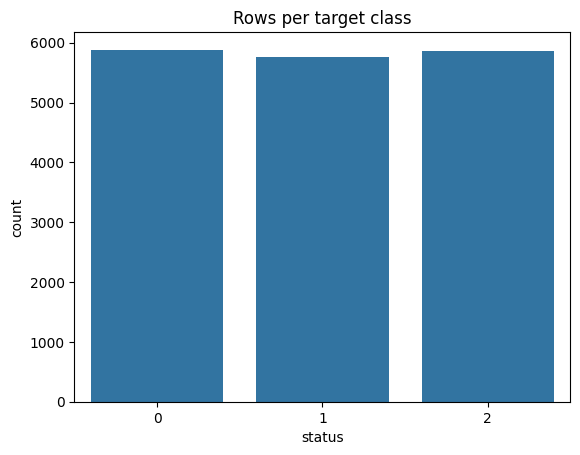

In [4]:
# --- Class balance ---
counts = df[TARGET].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")
sns.countplot(x=df[TARGET]); plt.title("Rows per target class"); plt.show()

In [5]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn mean/std from TRAIN only
X_test_s  = scaler.transform(X_test)        # reuse them on TEST (no leakage)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (13998, 21) | Test: (3500, 21)


## Step 2: KNN
First K=5, then every odd K from 1 to 15. I plot K against accuracy and pick the best K.

KNN (K=5) test accuracy: 0.3269


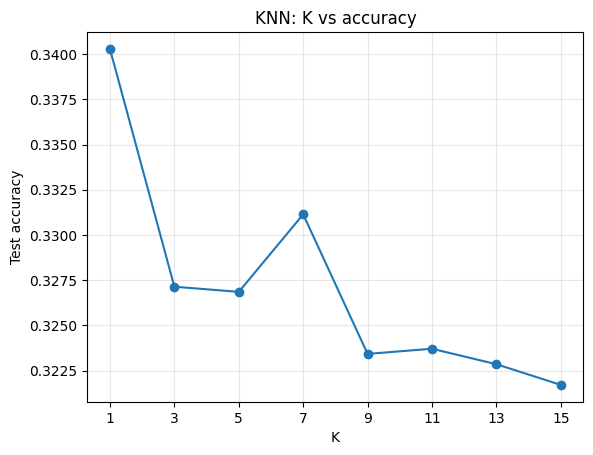

Best K: 1 | accuracy: 0.3403


In [6]:
knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
print("KNN (K=5) test accuracy:", round(knn5.score(X_test_s, y_test), 4))

k_values = list(range(1, 16, 2))
knn_acc = []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    knn_acc.append(accuracy_score(y_test, m.predict(X_test_s)))

plt.plot(k_values, knn_acc, marker="o")
plt.xticks(k_values); plt.xlabel("K"); plt.ylabel("Test accuracy"); plt.title("KNN: K vs accuracy"); plt.grid(alpha=.3)
plt.show()

best_k = k_values[int(np.argmax(knn_acc))]
print("Best K:", best_k, "| accuracy:", round(max(knn_acc), 4))
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)

**Why this K?** K is how many nearest neighbours vote on a prediction.

With K=1, the model copies the single closest training patient. It is very flexible: it follows every small detail of the training data, including random noise, so it can overfit. With a large K such as 15, many neighbours vote, so the model is smoother and less affected by single odd rows, but it can become too general and miss real local patterns. Normally the best K is somewhere in between.

In my results, K=1 had the highest accuracy (0.340), and accuracy dropped to about 0.327 at K=3 and K=5, then slowly to 0.322 at K=15. So K=1 "won", but I don't think it is a real win. It beats K=5 by only about 1.3 points, and the random guess level is 33.3%. Every K is within about 1 point of that line, and with 3,500 test rows a difference this small can happen by chance. The curve also has no clear shape (it goes up and down, for example K=7 is better than K=5 and K=9), which is what random noise looks like.

The reason there is no good K is that the features do not contain a pattern for status. With no pattern to find, neighbours that look similar do not share the same status, so changing K only changes which random guess I get. I chose K=1 because it had the highest accuracy, but in a real dataset I would trust a K only if the curve showed a clear peak, and I would choose it with cross-validation instead of the test set.

## Step 3: Decision Tree
I try `max_depth` = 2, 3, 5, 10 and None, and compare train accuracy with test accuracy to see overfitting.

  max_depth  train_acc  test_acc
0         2     0.3457    0.3337
1         3     0.3476    0.3329
2         5     0.3563    0.3374
3        10     0.4018    0.3317
4      None     1.0000    0.3303


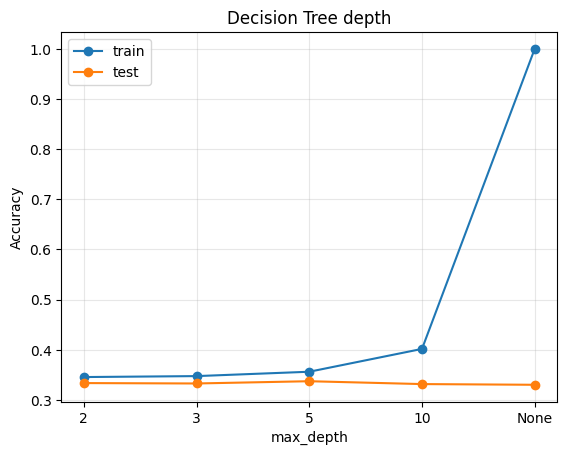

Best max_depth: 5


In [7]:
depths = [2, 3, 5, 10, None]
rows = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_s, y_train)
    rows.append({"max_depth": str(d),
                 "train_acc": round(t.score(X_train_s, y_train), 4),
                 "test_acc": round(t.score(X_test_s, y_test), 4)})
depth_df = pd.DataFrame(rows)
print(depth_df)

plt.plot(depth_df["max_depth"], depth_df["train_acc"], marker="o", label="train")
plt.plot(depth_df["max_depth"], depth_df["test_acc"], marker="o", label="test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Decision Tree depth"); plt.grid(alpha=.3); plt.show()

best_depth_str = depth_df.loc[depth_df["test_acc"].idxmax(), "max_depth"]
best_depth = None if best_depth_str == "None" else int(best_depth_str)
print("Best max_depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train_s, y_train)

## Step 4: Logistic Regression
Train the model and print the predicted probabilities for 5 test rows with `predict_proba`.

In [8]:
logreg = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
print("Logistic Regression test accuracy:", round(logreg.score(X_test_s, y_test), 4))

proba = logreg.predict_proba(X_test_s[:5])
out = pd.DataFrame(proba, columns=[f"P(class {c})" for c in logreg.classes_]).round(3)
out["predicted"] = logreg.predict(X_test_s[:5])
out["actual"] = y_test.values[:5]
out

Logistic Regression test accuracy: 0.3311


,P(class 0),P(class 1),P(class 2),predicted,actual
0,0.329,0.339,0.332,1,1
1,0.346,0.346,0.308,0,1
2,0.309,0.355,0.336,1,0
3,0.307,0.361,0.332,1,0
4,0.313,0.355,0.333,1,0


**Reading the probabilities:** For test row 0, the model gave Admitted 0.329, Discharged 0.339 and Under Treatment 0.332. It predicted Discharged because that class has the highest probability, and the prediction was correct (actual = Discharged). But the model is not sure at all. The three probabilities are almost equal, and the winning class beats the next one by only 0.007. With 3 classes, pure guessing would give about 0.333 each, so this is basically a coin flip that happened to land on the right answer.

The other rows show the same thing. In row 1, Admitted and Discharged are tied at 0.346 and the model picked Admitted, which was wrong (actual = Discharged). In rows 2, 3 and 4 it predicted Discharged with only 0.355 to 0.361 and all three were wrong (actual = Admitted). So only 1 of the 5 predictions was correct, which matches the overall accuracy of about 33%.

Across the whole test set, the highest probability the model ever gave to any class was only about 0.40, and on average it was about 0.35. A model that had really learned something would sometimes give 0.8 or 0.9 for a class. This tells me the features (age, gender, department, diagnosis, treatment, bill) do not help predict the patient's status.

## Step 5: Evaluate all three models
Accuracy, confusion matrix (heatmap), classification report, and one comparison table.

 KNN 
              precision    recall  f1-score   support

           0       0.35      0.35      0.35      1177
           1       0.33      0.34      0.33      1151
           2       0.34      0.33      0.34      1172

    accuracy                           0.34      3500
   macro avg       0.34      0.34      0.34      3500
weighted avg       0.34      0.34      0.34      3500

 Decision Tree 
              precision    recall  f1-score   support

           0       0.34      0.68      0.45      1177
           1       0.36      0.01      0.03      1151
           2       0.34      0.32      0.33      1172

    accuracy                           0.34      3500
   macro avg       0.34      0.34      0.27      3500
weighted avg       0.34      0.34      0.27      3500

 Logistic Regression 
              precision    recall  f1-score   support

           0       0.32      0.45      0.38      1177
           1       0.31      0.20      0.24      1151
           2       0.36      0.

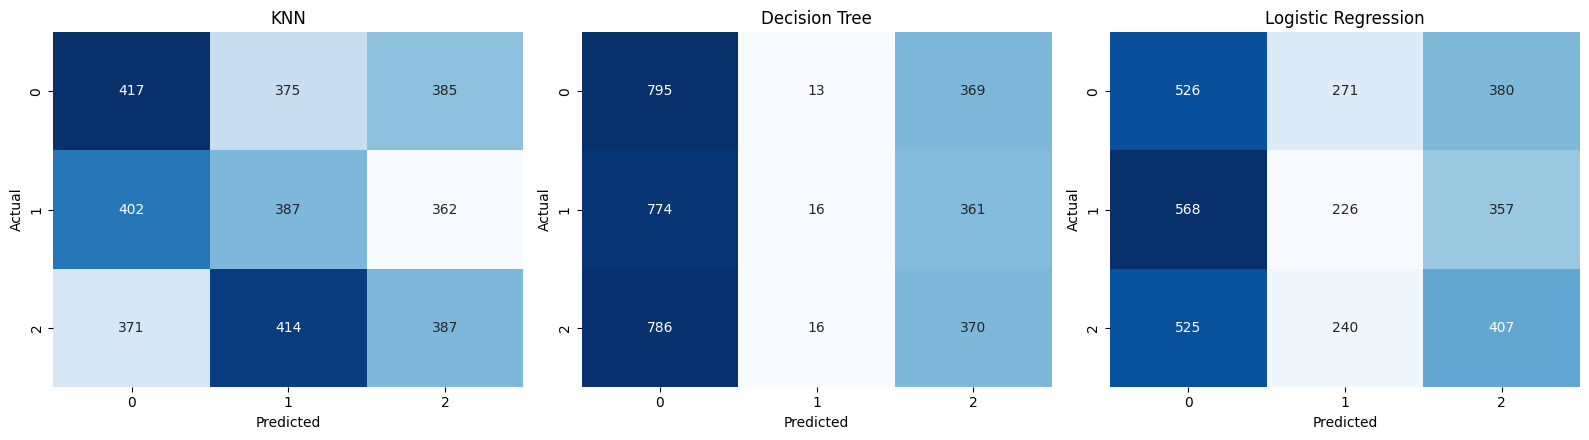

Precision/Recall/F1 use: weighted average


,Model,Accuracy,Precision,Recall,F1
0,KNN,0.3403,0.3403,0.3403,0.3403
1,Decision Tree,0.3374,0.3431,0.3374,0.2692
2,Logistic Regression,0.3311,0.3292,0.3311,0.3230


In [9]:
n_classes = y.nunique()
avg = "binary" if n_classes == 2 else "weighted"

models = {"KNN": knn, "Decision Tree": tree, "Logistic Regression": logreg}
results, preds = [], {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    p = m.predict(X_test_s); preds[name] = p
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    print("="*55, "\n", name, "\n", "="*55)
    print(classification_report(y_test, p))
    results.append({"Model": name,
                    "Accuracy":  round(accuracy_score(y_test, p), 4),
                    "Precision": round(precision_score(y_test, p, average=avg, zero_division=0), 4),
                    "Recall":    round(recall_score(y_test, p, average=avg, zero_division=0), 4),
                    "F1":        round(f1_score(y_test, p, average=avg, zero_division=0), 4)})
plt.tight_layout(); plt.show()

comparison = pd.DataFrame(results)
print("Precision/Recall/F1 use:", "the positive class (1)" if avg == "binary" else "weighted average")
comparison

In [10]:
best_name = comparison.sort_values(["F1", "Accuracy"], ascending=False).iloc[0]["Model"]
print("Best model by F1:", best_name)
print("Best K:", best_k, "| Best max_depth:", best_depth)

Best model by F1: KNN
Best K: 1 | Best max_depth: 5


### Extra: Linear Regression
Linear Regression predicts a number, not a class. As a quick experiment I fit it on the 0/1 target and turn its output into a class with a 0.5 threshold. This only works for a 2-class target.

In [11]:
if n_classes == 2:
    lin = LinearRegression().fit(X_train_s, y_train)
    raw = lin.predict(X_test_s)
    p_lin = (raw >= 0.5).astype(int)
    print("Raw outputs, first 5:", raw[:5].round(2), "<- note values can go below 0 or above 1")
    print("Accuracy:", round(accuracy_score(y_test, p_lin), 4), "| F1:", round(f1_score(y_test, p_lin), 4))
else:
    print("Skipped: target has more than 2 classes.")

Skipped: target has more than 2 classes.


**Why is Linear Regression a poor choice for classification?**

Linear Regression predicts a number on a continuous scale, such as a price or a temperature. Classification needs a class label, such as Admitted, Under Treatment or Discharged. There are three main problems with using Linear Regression for that:

1. **Its output is not a probability.** It can give values below 0 or above 1 (for example -0.3 or 1.4), which makes no sense as a chance of belonging to a class. Logistic Regression avoids this because it passes the result through a sigmoid curve, so outputs always stay between 0 and 1, and `predict_proba` gives proper probabilities.

2. **It treats the class numbers as real quantities.** My target is encoded as Admitted = 0, Discharged = 1, Under Treatment = 2. Linear Regression would assume that Under Treatment is "twice" Discharged and that Discharged sits halfway between the other two, which is false because these are just names with no order. It also cannot output a class directly, only a number I would have to cut with thresholds.

3. **It is sensitive to extreme values and does not fit the task.** It minimises squared error, so a few extreme rows can pull the line and shift the decision threshold. Logistic Regression is trained for classification, so it handles this better.

For my data, the code cell was skipped because my target has 3 classes. The simple 0.5 threshold only works with two classes (0 and 1). This is itself a sign that Linear Regression does not fit multi-class classification.

## Step 6: Explain my results
Write these in your own words (the prompts are there to guide you, delete them once you answer).

**1. Which model is best and why?** Use the comparison table (not only accuracy).

**2. Which mistake is worse for MY problem: false positive or false negative?** So does precision or recall matter more? Give a real-life reason from your dataset.

**3. Where does my best model make mistakes?** Look at the confusion matrix: how many FP and FN? Which class is harder?

In [12]:
# Mistakes of the best model
best_pred = preds[best_name]
cm = confusion_matrix(y_test, best_pred)
print(best_name); print(cm)
if n_classes == 2:
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

KNN
[[417 375 385]
 [402 387 362]
 [371 414 387]]


## BONUS: Is accuracy misleading?
I compare each model with a dummy that always predicts the biggest class. If the dummy gets high accuracy, accuracy alone hides how bad a model is on the small class.

'Always predict class 0' -> accuracy 0.3363, F1 0.1693


/tmp/ipykernel_396/2918420830.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  bonus.loc[len(bonus)] = ["Dummy (majority)", round(base_acc,4), None, None, round(base_f1,4), round(base_acc-base_f1,4)]


,Model,Accuracy,Precision,Recall,F1,Acc - F1 gap
0,KNN,0.3403,0.3403,0.3403,0.3403,0.0000
1,Decision Tree,0.3374,0.3431,0.3374,0.2692,0.0682
2,Logistic Regression,0.3311,0.3292,0.3311,0.3230,0.0081
3,Dummy (majority),0.3363,NaN,NaN,0.1693,0.1670


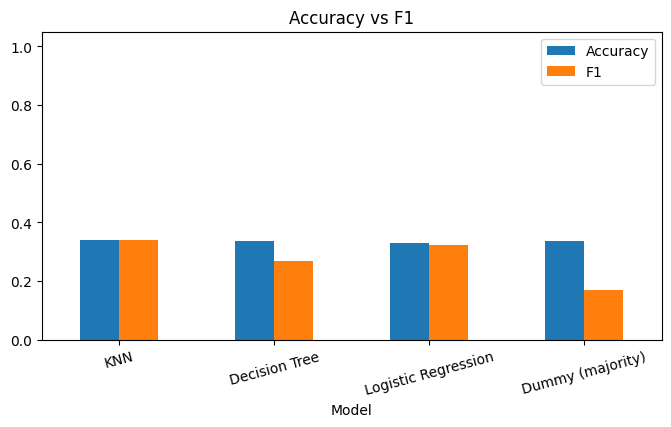

In [13]:
majority = y_train.mode()[0]
base_pred = np.full(len(y_test), majority)
base_acc = accuracy_score(y_test, base_pred)
base_f1 = f1_score(y_test, base_pred, average=avg, zero_division=0)
print(f"'Always predict class {majority}' -> accuracy {base_acc:.4f}, F1 {base_f1:.4f}")

bonus = comparison.copy()
bonus["Acc - F1 gap"] = (bonus["Accuracy"] - bonus["F1"]).round(4)
bonus.loc[len(bonus)] = ["Dummy (majority)", round(base_acc,4), None, None, round(base_f1,4), round(base_acc-base_f1,4)]
display(bonus)

bonus.set_index("Model")[["Accuracy", "F1"]].plot(kind="bar", figsize=(8,4), rot=15)
plt.ylim(0, 1.05); plt.title("Accuracy vs F1"); plt.show()

**Conclusion:** In my data the classes are balanced (about 33% each), so accuracy is not misleading in the usual way, where a model scores high just by predicting the biggest class. But accuracy is still misleading here in two other ways.

First, every model has an accuracy of about 33% (KNN 0.340, Decision Tree 0.337, Logistic Regression 0.331). The dummy model that always predicts "Admitted" gets 0.336, almost the same. So the accuracy numbers only look like results; in fact the models learned nothing useful.

Second, accuracy hides how the Decision Tree behaves. Its accuracy (0.337) is close to the others, but its F1 is only 0.269, a gap of 0.068. The classification report shows why: it almost never predicts "Discharged" (recall 0.01) and mostly predicts "Admitted". KNN has no gap between accuracy and F1 (both 0.340), and Logistic Regression has a very small gap (0.008), so they spread their guesses more evenly across the classes.

So F1 tells me more than accuracy because it shows which classes a model ignores. In the end, no model is good, because the features have no real link to the patient's status.